# 03: Classification: low / medium / high suitability

Regression predicts a number. Officers often want a **category** instead ("high PMKSY priority?"). This notebook makes classes from the scores and runs the Unit 3 classifiers on them.

**Tasks**
1. **Main task, `pmksy` terciles:** low / medium / high, with the two cut points computed on the **training split only**, so the test set can't influence where the class boundaries fall.
2. **Sanity task, `pm_kisan_score > 50`:** EDA F9 showed this equals `claim_type == "IFR"` on 100% of plots. Every reasonable classifier should score ≈100%; if one doesn't, the pipeline is broken.

**Same rules as 02:** the same 9 features, the same group split on `spatial_block`, tuning by GroupKFold, and a test set touched once.

> **Honesty note.** The labels come from `backend/services/scheme_rules.py` plus Gaussian noise. They are not real scheme allocations or eligibility decisions. A model scoring near the **R² ceiling** has recovered those rules. That is the best possible result here, and it says nothing about real-world accuracy, because no real outcome data exists yet. A score *above* the ceiling would mean leakage.

## 0. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ML = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fra_ml.py").exists() or (p / "ml" / "fra_ml.py").exists())
ML = ML if (ML / "fra_ml.py").exists() else ML / "ml"
sys.path.insert(0, str(ML))
from fra_ml import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (8, 4.5)})
pd.set_option("display.width", 200, "display.max_columns", 40)

df = load_data()
train, test = split(df)
print(f"train {len(train)} rows / {train.spatial_block.nunique()} blocks | test {len(test)} rows / {test.spatial_block.nunique()} blocks")
print("test rows per district:", test.district.value_counts().to_dict())

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, classification_report)
from sklearn.preprocessing import label_binarize

train 1211 rows / 92 blocks | test 329 rows / 23 blocks
test rows per district: {'Adilabad': 80, 'Shivpuri': 74, 'West Tripura': 72, 'Chhindwara': 32, 'Kandhamal': 31, 'Warangal': 29, 'Koraput': 11}


## 1. Make the classes (train-only cut points)

In [2]:
cuts = train.pmksy_score.quantile([1/3, 2/3]).to_numpy()
CLASSES = ["low", "medium", "high"]
def to_class(s): return pd.cut(s, [-np.inf, cuts[0], cuts[1], np.inf], labels=CLASSES).astype(str)
y_tr, y_te = to_class(train.pmksy_score), to_class(test.pmksy_score)
print("cut points (pmksy score):", cuts.round(2))
pd.DataFrame({"train": y_tr.value_counts(normalize=True), "test": y_te.value_counts(normalize=True)}).loc[CLASSES].round(3)

cut points (pmksy score): [48.15 68.27]


,train,test
pmksy_score,,
low,0.334,0.231
medium,0.333,0.328
high,0.334,0.441


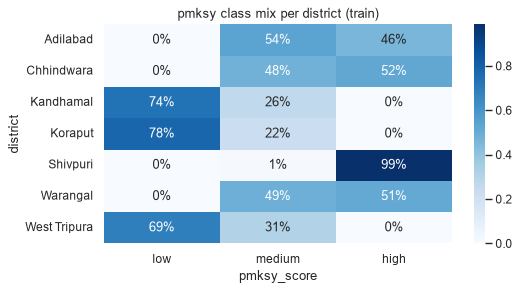

In [3]:
ct = pd.crosstab(train.district, y_tr, normalize="index").loc[:, CLASSES]
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", ax=ax); ax.set_title("pmksy class mix per district (train)")
plt.tight_layout(); plt.show()

The classes are **mostly decided by district** (EDA F1: district explains 87% of pmksy). So expect high accuracy everywhere, and most of the remaining mistakes on plots near a cut point, where label noise can flip the class.

## 2. The classifiers
| Model | Idea in one line | Needs scaling? |
|---|---|---|
| Logistic regression | linear score → softmax probability per class | yes |
| KNN | vote of the *k* most similar plots | yes (distance) |
| Linear SVM | widest-margin straight boundary | yes |
| Kernel SVM (RBF) | widest margin after an implicit curved mapping | yes |
| Gaussian Naive Bayes | Bayes' rule, assuming features independent within a class | no (but harmless) |
| Decision tree | yes/no questions down to a leaf | no (harmless) |

All of them are tuned with GroupKFold, scored on **macro-F1**, which averages F1 over the three classes so that no class is ignored.

In [4]:
CLFS = {
    "logistic regression": (LogisticRegression(max_iter=2000), {"model__C": [0.1, 1, 10, 100]}),
    "KNN": (KNeighborsClassifier(), {"model__n_neighbors": [3, 5, 9, 15, 25, 41], "model__weights": ["uniform", "distance"]}),
    "linear SVM": (SVC(kernel="linear", probability=True, random_state=SEED), {"model__C": [0.1, 1, 10]}),
    "kernel SVM (RBF)": (SVC(kernel="rbf", probability=True, random_state=SEED), {"model__C": [1, 10, 100], "model__gamma": ["scale", 0.05, 0.2]}),
    "naive Bayes": (GaussianNB(), {"model__var_smoothing": [1e-9, 1e-6, 1e-3]}),
    "decision tree": (DecisionTreeClassifier(random_state=SEED), {"model__max_depth": [2, 3, 4, 6, 8], "model__min_samples_leaf": [1, 5, 20]}),
}

def run_task(y_train, y_test, scoring="f1_macro"):
    out, models = [], {}
    for name, (est, grid) in CLFS.items():
        gs = GridSearchCV(make_pipe(clone(est)), grid, cv=group_cv(), scoring=scoring, n_jobs=-1)
        gs.fit(X_of(train), y_train, groups=train.spatial_block)
        m = gs.best_estimator_
        pred = m.predict(X_of(test)); proba = m.predict_proba(X_of(test))
        labels = list(m.classes_)
        if len(labels) == 2:
            auc = roc_auc_score(y_test == labels[1], proba[:, 1])
        else:
            auc = roc_auc_score(label_binarize(y_test, classes=labels), proba, average="macro", multi_class="ovr")
        p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
        # bootstrap 95% CI on test accuracy
        rng = np.random.default_rng(SEED); yt, pr = np.asarray(y_test), np.asarray(pred)
        boots = [accuracy_score(yt[i], pr[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
        out.append({"model": name, "params": json.dumps({k.replace("model__", ""): v for k, v in gs.best_params_.items()}),
                    "cv_f1_macro": gs.best_score_, "train_accuracy": accuracy_score(y_train, m.predict(X_of(train))),
                    "test_accuracy": accuracy_score(y_test, pred), "test_acc_ci_low": np.quantile(boots, 0.025),
                    "test_acc_ci_high": np.quantile(boots, 0.975), "test_precision_macro": p, "test_recall_macro": r,
                    "test_f1_macro": f, "test_auc": auc})
        models[name] = (m, pred, proba, labels)
    return pd.DataFrame(out).set_index("model"), models

res_t, models_t = run_task(y_tr, y_te)
res_t.drop(columns="params").round(3)

,cv_f1_macro,train_accuracy,test_accuracy,test_acc_ci_low,test_acc_ci_high,test_precision_macro,test_recall_macro,test_f1_macro,test_auc
model,,,,,,,,,
logistic regression,0.771,0.784,0.769,0.720,0.812,0.757,0.777,0.763,0.908
KNN,0.762,0.827,0.778,0.729,0.824,0.769,0.770,0.770,0.906
linear SVM,0.781,0.787,0.796,0.751,0.836,0.783,0.798,0.786,0.889
kernel SVM (RBF),0.768,0.789,0.796,0.754,0.836,0.783,0.798,0.786,0.898
naive Bayes,0.565,0.674,0.672,0.620,0.720,0.618,0.672,0.571,0.859
decision tree,0.772,0.805,0.769,0.717,0.812,0.767,0.760,0.763,0.909


## 3. Confusion matrices
Rows are the **true** class and columns the **predicted** class. The diagonal is correct. Mistakes between *low* and *high* would be serious; mistakes between neighbouring classes are expected near the cut points.

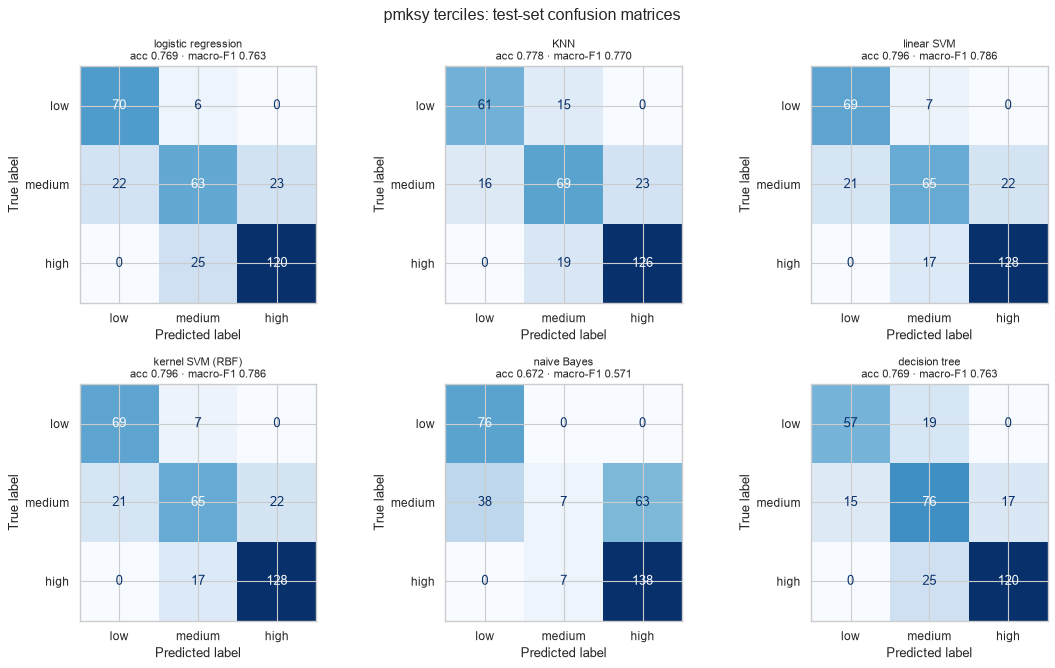

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, (name, (m, pred, proba, labels)) in zip(axes.flat, models_t.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=CLASSES), display_labels=CLASSES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nacc {res_t.loc[name, 'test_accuracy']:.3f} · macro-F1 {res_t.loc[name, 'test_f1_macro']:.3f}", fontsize=10)
fig.suptitle("pmksy terciles: test-set confusion matrices"); plt.tight_layout(); plt.show()

In [6]:
best_name = res_t.cv_f1_macro.idxmax()
print(f"Best by CV macro-F1: {best_name}\n")
print(classification_report(y_te, models_t[best_name][1], labels=CLASSES, digits=3))

Best by CV macro-F1: linear SVM

              precision    recall  f1-score   support

         low      0.767     0.908     0.831        76
      medium      0.730     0.602     0.660       108
        high      0.853     0.883     0.868       145

    accuracy                          0.796       329
   macro avg      0.783     0.798     0.786       329
weighted avg      0.793     0.796     0.791       329



**Precision vs recall in plain words:**
- **Precision** for *high* answers: of the plots we called high, how many really are high?
- **Recall** for *high* answers: of the truly high plots, how many did we catch?

A DSS that flags plots for priority attention should care most about **recall of "high"**, so that eligible plots aren't missed. Precision matters more when attention costs something.

## 4. ROC curves (one-vs-rest)
For each class, the ROC curve plots the true-positive rate against the false-positive rate as the probability threshold moves. **AUC** = 1.0 is perfect and 0.5 is a coin flip.

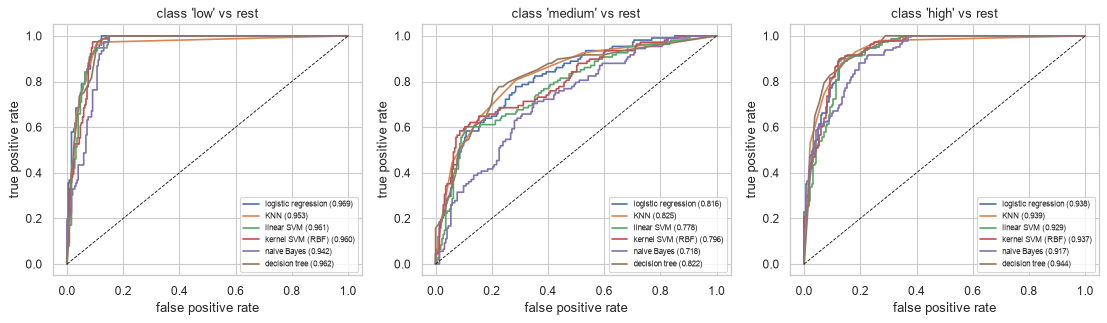

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, cls in zip(axes, CLASSES):
    for name, (m, pred, proba, labels) in models_t.items():
        fpr, tpr, _ = roc_curve(y_te == cls, proba[:, labels.index(cls)])
        ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_te == cls, proba[:, labels.index(cls)]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_title(f"class '{cls}' vs rest"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 5. Where errors happen: distance from the cut points
If the models have learned the rule, almost every mistake should sit near a class boundary, where noise (SD 4) can push a plot across.

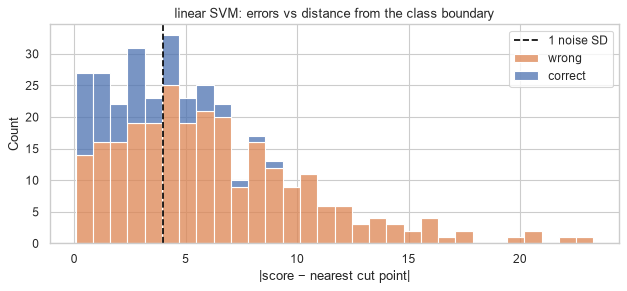

errors within 1 noise SD (4 pts) of a cut point: 69% of 67 errors


In [8]:
m, pred, proba, labels = models_t[best_name]
dist = np.min(np.abs(test.pmksy_score.to_numpy()[:, None] - cuts[None, :]), axis=1)
wrong = pred != y_te.to_numpy()
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(x=dist, hue=np.where(wrong, "wrong", "correct"), bins=30, multiple="stack", ax=ax)
ax.axvline(4, color="black", ls="--", label="1 noise SD"); ax.set_xlabel("|score − nearest cut point|"); ax.legend(["1 noise SD", "wrong", "correct"])
ax.set_title(f"{best_name}: errors vs distance from the class boundary"); plt.tight_layout(); plt.show()
print(f"errors within 1 noise SD (4 pts) of a cut point: {(dist[wrong] <= 4).mean():.0%} of {wrong.sum()} errors")

## 6. Sanity task: `pm_kisan_score > 50`
EDA F9 showed this class equals `claim_type == "IFR"` exactly. A working pipeline must score ≈100% here.

,cv_f1_macro,test_accuracy,test_f1_macro,test_auc
model,,,,
logistic regression,1.0,1.0,1.0,1.0
KNN,1.0,1.0,1.0,1.0
linear SVM,1.0,1.0,1.0,1.0
kernel SVM (RBF),1.0,1.0,1.0,1.0
naive Bayes,1.0,1.0,1.0,1.0
decision tree,1.0,1.0,1.0,1.0


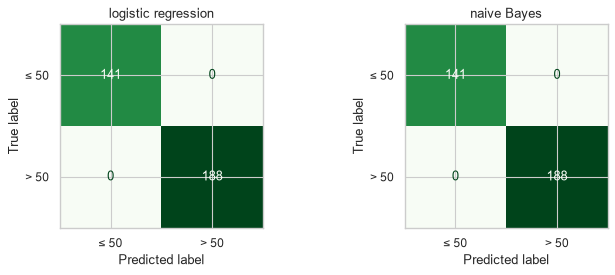

In [9]:
ys_tr = (train.pm_kisan_score > 50).map({True: "above 50", False: "50 or below"})
ys_te = (test.pm_kisan_score > 50).map({True: "above 50", False: "50 or below"})
res_s, models_s = run_task(ys_tr, ys_te)
display(res_s[["cv_f1_macro", "test_accuracy", "test_f1_macro", "test_auc"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, ["logistic regression", "naive Bayes"]):
    ConfusionMatrixDisplay(confusion_matrix(ys_te, models_s[name][1], labels=["50 or below", "above 50"]),
                           display_labels=["≤ 50", "> 50"]).plot(ax=ax, colorbar=False, cmap="Greens")
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 7. Cross-validation and resampling, recapped
- **GroupKFold (5 folds) on `spatial_block`:** each fold holds out whole blocks, every plot is validated once, and the score is the average. This is used for every tuning choice above.
- **Bootstrapping:** the 95% intervals on test accuracy come from resampling the test rows 1,000 times with replacement. Narrow intervals mean the test set is big enough to tell models apart; overlapping intervals mean the models are tied.
- **The test set** was used once per model, after tuning, and never for choosing anything.

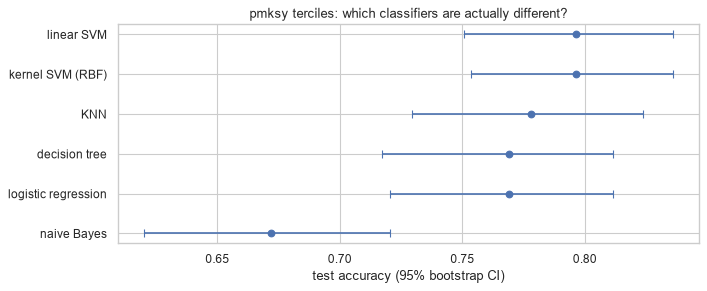

In [10]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
out = pd.concat([res_t.assign(task="pmksy terciles (train cuts)"), res_s.assign(task="sanity: pm_kisan > 50")]).reset_index()
num = out.select_dtypes("number").columns; out[num] = out[num].round(4)
out.to_csv(RESULTS_DIR / "classification_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
r = res_t.sort_values("test_accuracy")
ax.errorbar(r.test_accuracy, range(len(r)), xerr=[r.test_accuracy - r.test_acc_ci_low, r.test_acc_ci_high - r.test_accuracy], fmt="o", capsize=4)
ax.set_yticks(range(len(r))); ax.set_yticklabels(r.index); ax.set_xlabel("test accuracy (95% bootstrap CI)")
ax.set_title("pmksy terciles: which classifiers are actually different?"); plt.tight_layout(); plt.show()

## 8. Takeaways (numbers from the run above, seed 42)
- **Five of six classifiers are statistically tied** at 0.77–0.80 test accuracy (macro-F1 0.76–0.79, AUC ≈ 0.89–0.91), with overlapping bootstrap intervals. Linear SVM has the best CV macro-F1 (0.781). The choice of classifier matters much less than the features and the split.
- **Naive Bayes is the clear loser** (0.67 accuracy, macro-F1 0.57). Its "features are independent within a class" assumption is badly wrong here: rainfall and groundwater are the same district fact counted twice, and several features are 0/1 flags, not Gaussian.
- **"Medium" is the hard class** (recall 0.60 for linear SVM). It is squeezed between two cut points, so noise can push a plot out on either side.
- **Most errors are boundary noise:** 69% of linear SVM's 67 errors sit within one noise SD (4 points) of a cut point.
- **The test class mix differs from train** (44% "high" vs 33%), because the test blocks over-represent Shivpuri and Adilabad. Accuracy on another split would shift a little.
- **The sanity task is 100% for every model**, which proves features, encoding and split are wired correctly.
- **The deployed DSS uses the regression models from 02**, not these classifiers. A category can be derived from a predicted score with the same train-only cut points if the UI ever needs one.